# Part 1: The Data, and an Image as Numbers

## Task 1.1: Imports, GPU check, and class counts

In [2]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


## Task 1.2: Look at the images, then at the numbers

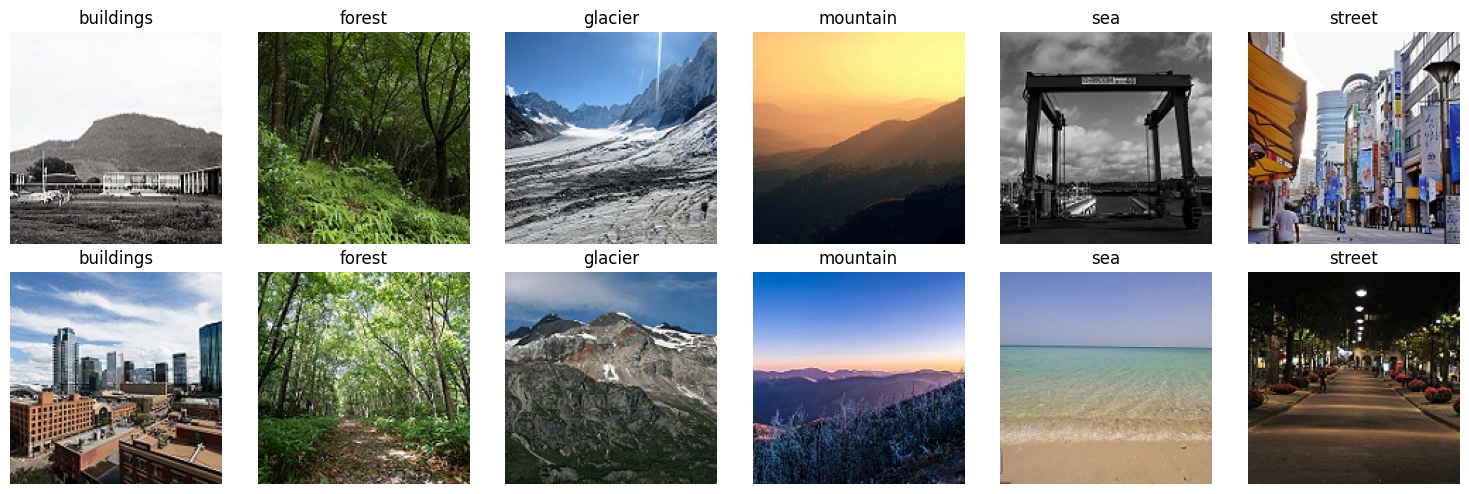

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [3]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

## Part 1: The Data, and an Image as Numbers

### Objective
The objective of this part is to understand the Intel Image Classification dataset, verify that the GPU is available, examine the number of images in each class, and understand how a digital image is represented numerically.

### What We Are Doing
First, we import the required libraries, including PyTorch, NumPy, Matplotlib, PIL, and tools from torchvision. We then check whether a GPU is available so that deep learning operations can run efficiently.

Next, we define the paths to the training and testing folders of the Intel Image Classification dataset. We inspect the class folders and count the images available in each class.

The dataset contains six scene categories:

- Buildings
- Forest
- Glacier
- Mountain
- Sea
- Street

We then display sample images from these categories to visually inspect the dataset. Finally, we convert an image into a NumPy array and examine its shape, data type, minimum value, maximum value, and a small section of its red color channel.

### Why This Matters
A deep learning model does not understand images in the same way that humans do. It processes numerical tensors containing pixel values. Examining the images and their numerical representation helps us understand the data that will be provided to the neural network.



# Part 2: Convolution and Parameters by Hand

## Task 2.1: Reproduce the lecture's convolution

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


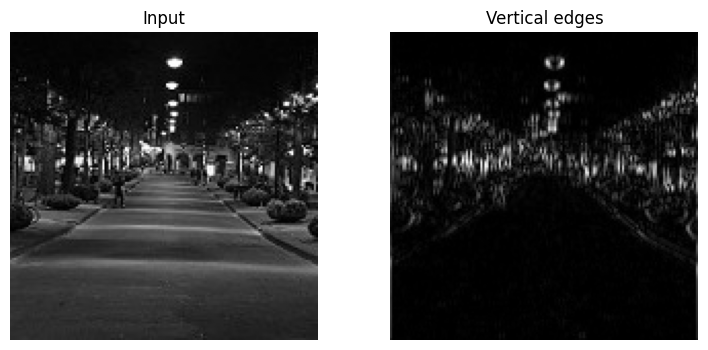

In [4]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

## Task 2.2: Why convolutions, in numbers

In [5]:
def count(m):
    return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')  # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')  # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


## Part 2: Convolution and Parameters by Hand

### Objective
The objective of this part is to understand how convolution works on images, how a convolutional layer detects visual features, how output dimensions are calculated, and how to count the parameters of convolutional and dense layers.

### What We Are Doing
First, we create a simple 5 × 5 image containing a vertical edge and apply a 3 × 3 convolution kernel. The kernel contains the values `[-1, 0, 1]` in each row and responds to changes in pixel intensity from left to right.

We compare the resulting convolution output with the expected result from the lecture. We then apply the same kernel to a real image converted to grayscale and visualize the detected vertical edges.

Next, we create a convolutional layer with three input channels and 64 output channels, along with a dense layer. We calculate and compare their parameter counts.

We also test convolution layers with different stride values and apply 2 × 2 max pooling to observe how these operations affect the output tensor dimensions.

### Why This Matters
Convolutional neural networks use filters to identify patterns such as edges, textures, and shapes. Parameter counting helps us understand why convolutional layers can process images using far fewer parameters than large dense layers.

Weight sharing allows the same filter to detect a feature at different spatial locations in an image.



# Part 3: Transforms and Data Loaders

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


## Part 3: Transforms and Data Loaders

### Objective
The objective of this part is to prepare the image dataset for ResNet-18 by applying the required transformations, dividing the data into training and validation sets, and creating DataLoaders for training, validation, and testing.

### What We Are Doing
A pretrained ResNet-18 model expects images resized to 224 × 224 pixels and normalized using the mean and standard deviation associated with ImageNet.

We create two sets of transformations. The training transformations include random resized cropping, horizontal flipping, and changes in brightness and contrast. These operations introduce variation into the training images and help the model learn more robust features.

The evaluation transformations resize the images and normalize them without applying random augmentation. This ensures that validation and test images are evaluated consistently.

We load the training folder twice: once with the training transformations and once with the evaluation transformations. We use the same randomly selected indices to create a training split and a validation split, so the two sets do not overlap. The test set is loaded separately from the test directory.

Finally, we create three DataLoaders: `train_dl`, `val_dl`, and `test_dl`.

### Why This Matters
The training set is used to update the model's parameters. The validation set is used to compare model performance and select the best training epoch. The test set is reserved for the final evaluation and must not be used to make training or model-selection decisions.

Applying augmentation only to training images prevents random transformations from affecting validation and test evaluation.



# Part 4: The Training Loop and Feature Extraction

## Task 4.1: A reusable training loop

In [20]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n
def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

## Task 4.2: Freeze the body, train a new head

In [28]:

import torch
import torch.nn as nn
from torchvision import models

# Load ResNet18 without downloading pretrained weights
model = models.resnet18(weights=None)

# Freeze the body
for p in model.parameters():
    p.requires_grad = False

# Replace the final layer with a new classification head
model.fc = nn.Linear(model.fc.in_features, len(classes))

# Move model to GPU if available, otherwise CPU
model = model.to(device)

# Count trainable parameters
trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total = sum(p.numel() for p in model.parameters())

print(f"Trainable: {trainable:,} of {total:,} parameters")

# Train the classification head
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

best = fit(model, opt, epochs=3, history=history)

print(f"Best validation accuracy, feature extraction: {best:.3f}")


Trainable: 3,078 of 11,179,590 parameters
epoch 1: train loss 1.524 acc 0.369 | val loss 1.353 acc 0.479 (76s)
epoch 2: train loss 1.357 acc 0.470 | val loss 1.290 acc 0.507 (34s)
epoch 3: train loss 1.297 acc 0.497 | val loss 1.221 acc 0.526 (34s)
Best validation accuracy, feature extraction: 0.526


## Part 4: The Training Loop and Feature Extraction

### Objective
The objective of this part is to implement a reusable training loop and use transfer learning to train a new classification head on a pretrained ResNet-18 model while keeping the rest of the network frozen.

### What We Are Doing

**Task 4.1: A Reusable Training Loop**

We define a function called `run_epoch()` to perform one pass through the dataset. During training, the function performs the forward pass, calculates the cross-entropy loss, clears the previous gradients, performs backpropagation, and updates the model parameters.

We also define a `fit()` function that trains the model for a specified number of epochs. After every epoch, it evaluates the model on the validation set, records the training and validation loss and accuracy, and saves the model weights from the epoch with the best validation accuracy.

**Task 4.2: Freeze the Body and Train a New Head**

We load ResNet-18 with pretrained ImageNet weights. We freeze the existing parameters so that the previously learned features are not updated during the first training phase.

We replace the final fully connected layer with a new layer containing six output classes, corresponding to the six scene categories in the Intel Image Classification dataset.

We then count the trainable parameters and use the Adam optimizer to train only the new classification head for three epochs.

The new classification head has 3,078 trainable parameters: 512 × 6 weights plus 6 bias values. This is approximately 0.03% of the network's parameters.

### Why This Matters
Transfer learning allows us to reuse visual features learned from a large dataset instead of training an entire network from scratch. The early and intermediate layers of ResNet-18 already contain useful visual features, so we initially train only the new classification head to adapt the model to our six scene categories.



# Part 5: Fine-Tuning and Learning Curves

## Task 5.1: Unfreeze layer4 with a smaller learning rate

In [29]:
for p in model.layer4.parameters():
    p.requires_grad = True                     # unfreeze the last block
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},  # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])     # faster: new head
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 1.007 acc 0.613 | val loss 1.015 acc 0.624 (33s)
epoch 2: train loss 0.852 acc 0.683 | val loss 0.940 acc 0.647 (34s)
epoch 3: train loss 0.776 acc 0.711 | val loss 0.779 acc 0.724 (35s)
Best validation accuracy, fine-tuned: 0.724


## Task 5.2: Plot the learning curves

## Part 5: Fine-Tuning and Learning Curves

### Objective
The objective of this part is to improve the model through fine-tuning and compare the model's performance before and after unfreezing the final block of ResNet-18. We also plot learning curves to understand how the model learns over time.

### What We Are Doing

**Task 5.1: Unfreeze Layer4 with a Smaller Learning Rate**

In Part 4, we trained only the new classification head. In this part, we unfreeze the parameters of `layer4`, the final major block of ResNet-18, so that these pretrained features can adapt to the scene classification task.

We use two learning rates with the Adam optimizer:

- `1e-4` for `layer4`, allowing the pretrained parameters to change gradually.
- `1e-3` for the new fully connected classification head, allowing the newly added parameters to learn more quickly.

We train for another three epochs and record the best validation accuracy.

**Task 5.2: Plot the Learning Curves**

We use the recorded training history to plot two graphs:

1. Training and validation loss across all epochs.
2. Training and validation accuracy across all epochs.

A vertical line marks where fine-tuning begins, after the first three feature-extraction epochs.

### Why This Matters
Fine-tuning allows the pretrained network to adapt its higher-level features to the new dataset. Using a smaller learning rate for the pretrained block helps preserve useful features while adjusting them to the current task.

Learning curves help us understand whether the model is improving, whether validation performance is following training performance, and whether there are signs of overfitting.

Training accuracy may sometimes be lower than validation accuracy because the training images are randomly augmented, making them more challenging than the unaugmented validation images.



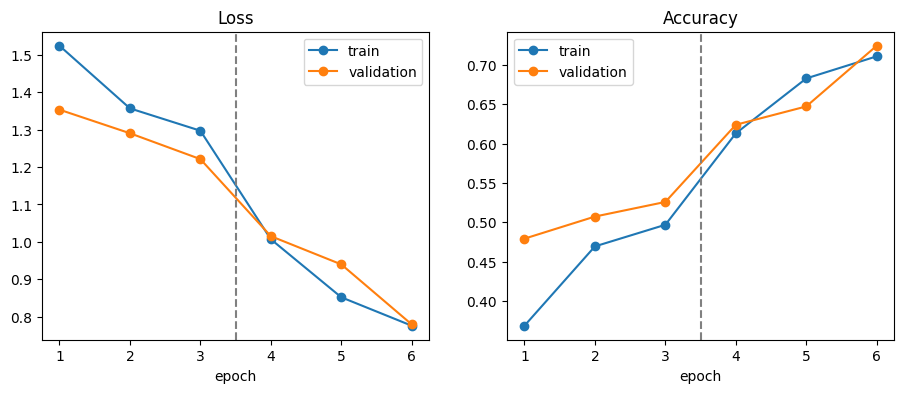

In [30]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--')   # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

# Part 6: Test Once, Then Study the Errors

## Task 6.1: Test-set evaluation

Test accuracy: 0.725
              precision    recall  f1-score   support

   buildings      0.757     0.577     0.655       437
      forest      0.969     0.787     0.868       474
     glacier      0.747     0.694     0.720       553
    mountain      0.620     0.785     0.692       525
         sea      0.630     0.692     0.660       510
      street      0.737     0.798     0.766       501

    accuracy                          0.725      3000
   macro avg      0.743     0.722     0.727      3000
weighted avg      0.740     0.725     0.727      3000



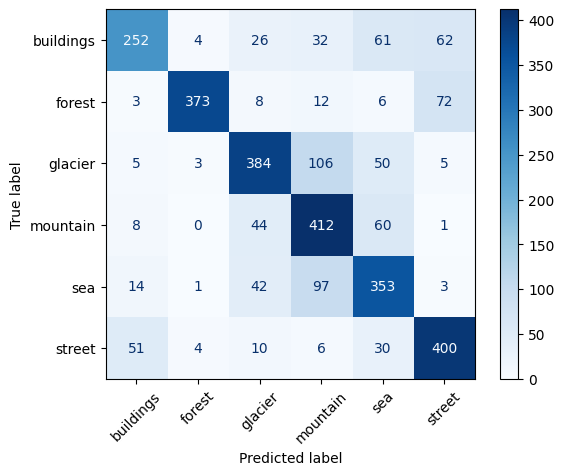

In [31]:
model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)
print(f'Test accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

## Task 6.2: Error gallery

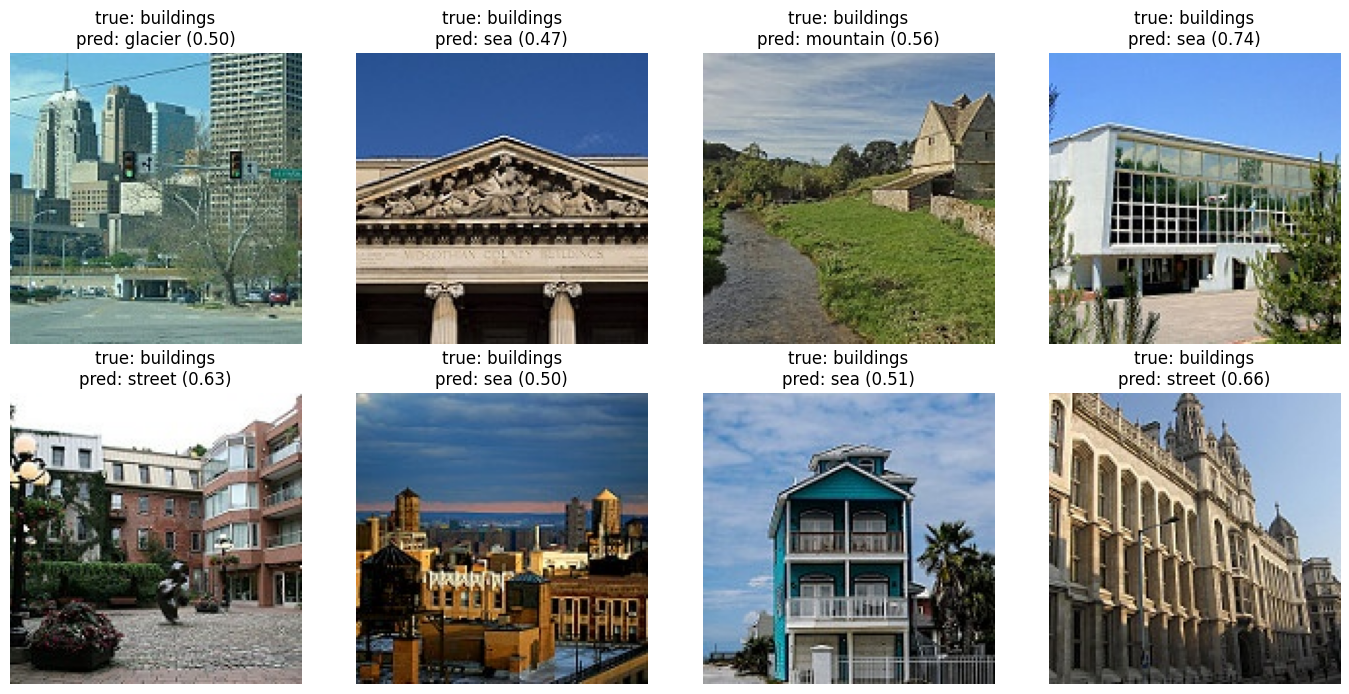

In [32]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

## Task 6.3: Inside one prediction

In [33]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   2.61   probability 0.840
forest     logit  -6.12   probability 0.000
glacier    logit   0.04   probability 0.064
mountain   logit  -0.42   probability 0.040
sea        logit  -0.46   probability 0.039
street     logit  -1.29   probability 0.017


## Part 6: Test Once, Then Study the Errors

### Objective
The objective of this part is to evaluate the final model on the test dataset, examine its classification performance, visualize its mistakes, and understand how the model produces probabilities for different classes.

### What We Are Doing

**Task 6.1: Test-Set Evaluation**

We switch the model to evaluation mode and use `torch.no_grad()` to prevent gradient calculations during testing. We pass the test images through the trained model and apply softmax to convert the output logits into probabilities.

We calculate the overall test accuracy and generate a classification report containing precision, recall, and F1-score for each class. We also create a confusion matrix to compare the actual class labels with the predicted labels.

**Task 6.2: Error Gallery**

We identify up to eight incorrectly classified test images and display them in an error gallery. Each image is labeled with its true class, predicted class, and the model's highest predicted probability.

This allows us to examine the images that the model finds difficult to classify.

**Task 6.3: Inside One Prediction**

We select one test image and display its true class. We then examine the model's logits and softmax probabilities for all six classes.

The logits are the raw outputs of the network. Softmax converts these outputs into probabilities that sum to 1, making it easier to compare the model's confidence across the six classes.

### Why This Matters
Overall accuracy does not tell us everything about a model's performance. A classification report shows how well the model identifies each class, while the confusion matrix reveals which classes are frequently mistaken for one another.

The error gallery helps us investigate whether an incorrect prediction results from a model limitation, a potentially incorrect label, or genuine ambiguity in the image.

The test set should be used for the final evaluation, not for choosing epochs or adjusting the model.



# Part 7: Save and Share

In [34]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


## Conclusion and Summary

In this lab, I learned the fundamental concepts of deep learning, convolutional neural networks, and transfer learning through the Intel Image Classification dataset. I explored how images are represented as numerical tensors, applied convolution operations to detect image features, and calculated the number of parameters in convolutional and dense layers.

I prepared the dataset using image transformations, data augmentation, and separate training, validation, and testing sets. I then used a pretrained ResNet-18 model to perform feature extraction by training a new classification head with only 3,078 trainable parameters. After that, I fine-tuned the final network block using different learning rates to adapt the model to the six scene categories.

I also examined training and validation loss and accuracy through learning curves. Finally, I evaluated the model on the test dataset, generated a classification report and confusion matrix, analyzed incorrectly classified images, and explored how softmax converts model outputs into probabilities.

Overall, this lab helped me understand how transfer learning can reuse previously learned visual features, how model performance can be evaluated, and why error analysis is important for understanding a deep learning model's limitations. These concepts will help me prepare for developing a deep learning project using a domain-specific dataset in Week 6.